In [1]:
## Plot soil moisture at flux tower sites compared to FATES

In [1]:
import numpy as np
#
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
## this next library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
import pandas as pd
from scipy.ndimage import uniform_filter1d


ERROR 1: PROJ: proj_create_from_database: Open of /global/homes/j/jkowalcz/.conda/envs/myenv/share/proj failed


In [2]:
## Paracou, French Guiana
par_lat=5.2787
par_lon=360.-52.9248
par_dt=-3 ## time in CSV file is local time, so we don't need to apply this to observed data

### Tapajos (TAP) - Brazil - UTC-3
tap_lat=-3.3  
tap_lon=305.0
tap_dt=-4 # solar time is UTC - 3.5
tap_dt2=-3 # flux tower data timestamp is beginning of measurement interval

## Tanguro - Brazil
tan_lat = -13.08 
tan_lon = 307.59
tan_dt = -4 # GMT-4 -- for FATES simulations
tan_dt2 = 0 ## flux tower data is in local time

## K34 -- Brazil
k34_lat = -2.6091
k34_lon = 360.-60.2093
k34_dt = -4

In [3]:
fates_days=np.linspace(1,365,365,dtype=np.int32)

In [4]:
## FATES 
tag='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'
file0=tag+'.elm.h0.cat.nc' # should be monthly output
d0 = xr.open_dataset(path+file0)

In [5]:
root_vwc=d0.FATES_ROOTWGT_SOILVWC.groupby("time.month").mean("time").mean("lon").mean("lat")

In [6]:
root_vwcsat=d0.FATES_ROOTWGT_SOILVWCSAT.groupby("time.month").mean("time").mean("lon").mean("lat")

Text(0.5, 0, 'Month')

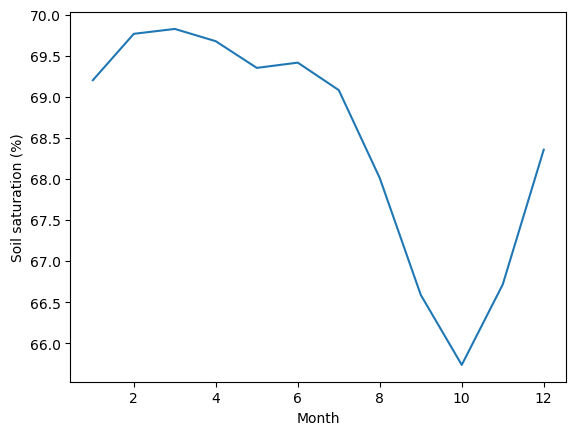

In [7]:
(100.*root_vwc/root_vwcsat).plot(x="month")
plt.ylabel("Soil saturation (%)")
plt.xlabel("Month")

In [9]:
fates_soil_sat=100.*(d0.FATES_ROOTWGT_SOILVWC/d0.FATES_ROOTWGT_SOILVWCSAT).groupby("time.month").mean("time")

In [10]:
# Define sites and real-world coordinates
site_names = ['par', 'tap', 'tan', 'k34']
target_lats = [par_lat, tap_lat, tan_lat, k34_lat]
target_lons = [par_lon, tap_lon, tan_lon, k34_lon]

# Wrap in DataArrays along a new 'site' dimension
site_lats = xr.DataArray(target_lats, dims="site", coords={"site": site_names})
site_lons = xr.DataArray(target_lons, dims="site", coords={"site": site_names})

# Extract all sites at once with nearest-neighbor lookup
all_sites_soil_sat = fates_soil_sat.sel(
    lat=site_lats, 
    lon=site_lons, 
    method="nearest"
)


In [50]:
all_sites_btran=d0.BTRAN.groupby("time.month").mean("time").sel(
    lat=site_lats, 
    lon=site_lons, 
    method="nearest"
)
    

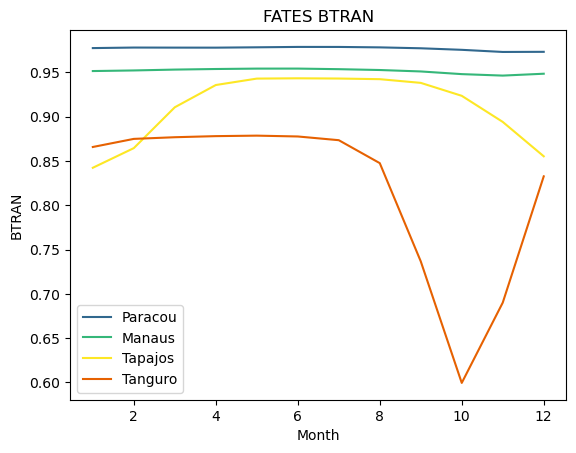

In [52]:
site_colors = ['#31688e', '#35b779', '#fde725','#e66101']
all_sites_btran.sel(site="par").plot(x="month",label="Paracou",color=site_colors[0])
all_sites_btran.sel(site="k34").plot(x="month",label="Manaus",color=site_colors[1])
all_sites_btran.sel(site="tap").plot(x="month",label="Tapajos",color=site_colors[2])
all_sites_btran.sel(site="tan").plot(x="month",label="Tanguro",color=site_colors[3])
plt.ylabel("BTRAN")
plt.xlabel("Month")
plt.title("FATES BTRAN")
plt.legend(loc='lower left')

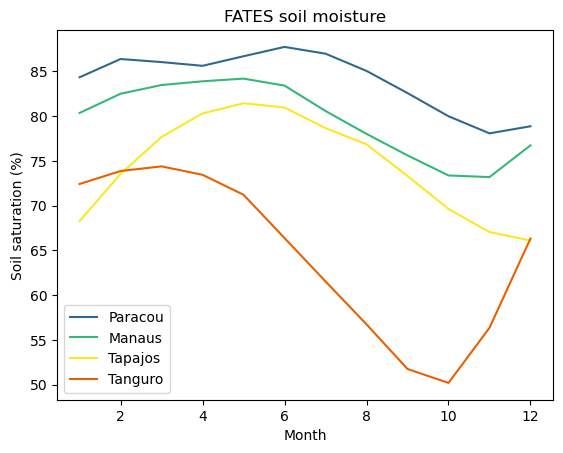

In [48]:
site_colors = ['#31688e', '#35b779', '#fde725','#e66101']
all_sites_soil_sat.sel(site="par").plot(x="month",label="Paracou",color=site_colors[0])
all_sites_soil_sat.sel(site="k34").plot(x="month",label="Manaus",color=site_colors[1])
all_sites_soil_sat.sel(site="tap").plot(x="month",label="Tapajos",color=site_colors[2])
all_sites_soil_sat.sel(site="tan").plot(x="month",label="Tanguro",color=site_colors[3])
plt.ylabel("Soil saturation (%)")
plt.xlabel("Month")
plt.title("FATES soil moisture")
plt.legend(loc='lower left')

In [49]:
d0

<xarray.Dataset>
Dimensions:                             (levgrnd: 15, levlak: 10, levdcmp: 15,
                                         levsoi: 10, fates_levscls: 13,
                                         fates_levscag: 91, fates_levscpf: 26,
                                         fates_levcacls: 2, fates_levcapf: 4,
                                         fates_levage: 7, fates_levpft: 2,
                                         fates_levlanduse: 5, fates_levfuel: 6,
                                         ...
                                         fates_levelage: 7,
                                         fates_levagefuel: 42,
                                         fates_levcdsc: 26, fates_levcdpf: 52,
                                         fates_levcdam: 2, time: 300,
                                         hist_interval: 2, lon: 24, lat: 23,
                                         fates_levlulu: 25, ltype: 9, natpft: 17)
Coordinates: (12/19)
  * levgrnd                             (levgrnd) float32 0.007101 ... 35.18
  * levlak                              (levlak) float32 0.05 0.6 ... 44.78
  * levdcmp                             (levdcmp) float32 0.007101 ... 35.18
  * levsoi                              (levsoi) float32 0.007101 ... 2.865
  * fates_levscls                       (fates_levscls) float32 0.0 ... 100.0
  * fates_levcacls                      (fates_levcacls) float32 0.0 5.0
    ...                                  ...
  * fates_levheight                     (fates_levheight) float32 0.0 ... 10.0
  * fates_levelem                       (fates_levelem) int32 1
  * fates_levcdam                       (fates_levcdam) float32 0.0 80.0
  * time                                (time) object 0001-02-01 00:00:00 ......
  * lon                                 (lon) float32 275.0 277.5 ... 332.5
  * lat                                 (lat) float32 -25.58 -23.68 ... 16.11
Dimensions without coordinates: fates_levscag, fates_levscpf, fates_levcapf,
                                fates_levcnlf, fates_levcnlfpf,
                                fates_levscagpf, fates_levagepft,
                                fates_levelpft, fates_levelcwd, fates_levelage,
                                fates_levagefuel, fates_levcdsc, fates_levcdpf,
                                hist_interval, fates_levlulu, ltype, natpft
Data variables: (12/656)
    fates_scmap_levscag                 (fates_levscag) int32 ...
    fates_agmap_levscag                 (fates_levscag) int32 ...
    fates_pftmap_levscpf                (fates_levscpf) int32 ...
    fates_scmap_levscpf                 (fates_levscpf) int32 ...
    fates_pftmap_levcapf                (fates_levcapf) int32 ...
    fates_camap_levcapf                 (fates_levcapf) int32 ...
    ...                                  ...
    WA                                  (time, lat, lon) float32 ...
    WASTEHEAT                           (time, lat, lon) float32 ...
    WIND                                (time, lat, lon) float32 ...
    ZBOT                                (time, lat, lon) float32 ...
    ZWT                                 (time, lat, lon) float32 ...
    ZWT_PERCH                           (time, lat, lon) float32 ...
Attributes: (12/28)
    title:                                     ELM History file information
    source:                                    E3SM Land Model
    source_id:                                 2d74f509c8
    product:                                   model-output
    realm:                                     land
    case:                                      hydro_comp_bmort_kmax_tune_sap...
    ...                                        ...
    ltype_deep_lake:                           5
    ltype_wetland:                             6
    ltype_urban_tbd:                           7
    ltype_urban_hd:                            8
    ltype_urban_md:                            9
    NCO:                                 

In [11]:
# d0.RAIN in mm/s
# get monthly average rainfall
fates_avg_rain = d0.RAIN.groupby('time.month').mean(dim='time')
# multiply by seconds per month to get total monthly rainfall in mm
sec_per_month=3.156e+7/12.
gswp_rain=sec_per_month*fates_avg_rain.sel(
    lat=site_lats, 
    lon=site_lons, 
    method="nearest"
).data

In [12]:
## Get flux tower data

In [13]:
## read in Paracou flux tower data
# Note: ICOS dataset is 2017-2024
# we want 2004-2014 to overlap with FATES forcing (1990-2014)

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
par_file='Guyaflux/data.csv'
# missing data in this file is empty -- automatically converted to NaN by Pandas

par_df = pd.read_csv(flx_path+par_file, sep=',')

# =====================================================================
# 1. TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
par_raw_counts_per_day = par_df.groupby(['Year', 'Julian Day']).size()
avg_par_raw_rows = par_raw_counts_per_day.mean()

print("--- Paracou Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_par_raw_rows:.2f}")

if 22 <= avg_par_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_par_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print("-> Warning: Unexpected row count. Verify dataset formatting.")
print("------------------------------------------\n")

--- Paracou Temporal Resolution Check ---
Average raw data rows per day: 48.00
-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)
-> Suggested diurnal filter threshold: 38 rows (~80%)
------------------------------------------



In [14]:
par_df.columns.tolist()

['TimeB',
 'Year',
 'Month',
 'Julian Day',
 'Hour/min',
 'time',
 'Temp(55)',
 'Hr(55)',
 'Rg',
 'Tsoil(CS615)',
 'SWC615',
 'Patm',
 'Wind-D',
 'Wind-S',
 'Rain',
 'VPD55',
 'Rn(55m)',
 'ETP',
 'ETP New CNR4',
 'SWC (-10 cm)',
 'SWC (-20 cm)',
 'SWC (-80 cm)',
 'SWC (-160 cm)',
 'SWC (-260 cm)',
 'LE(O)corr',
 'H',
 'Ustar',
 'NEE',
 'NEE_f',
 'Reco-R',
 'GPP-R',
 'Reco-L',
 'GPP-L',
 'Fc',
 'Storage',
 'LE_f',
 'H_f',
 'CNR4_temp',
 'CNR4_SW_up',
 'CNR4_SW_dn',
 'CNR4_LW_up',
 'CNR4_LW_dn',
 'CNR4_Rn',
 'VWC_10cm',
 'VWC_20cm',
 'VWC_80cm',
 'VWC_140cm',
 'VWC_190cm',
 'T_10cm',
 'T_20cm',
 'T_80cm',
 'T_140cm',
 'T_190cm',
 'Rain précis']

In [16]:
# =====================================================================
# 2. RUN SEPARATE DIURNAL COVERAGE FILTERS
# =====================================================================
# Count valid timesteps per day (Pandas ignores NaNs automatically)
par_df['counts_10'] = par_df.groupby(['Year', 'Julian Day'])['VWC_10cm'].transform('count')
par_df['counts_20']  = par_df.groupby(['Year', 'Julian Day'])['VWC_20cm'].transform('count')
par_df['counts_80']  = par_df.groupby(['Year', 'Julian Day'])['VWC_80cm'].transform('count')
par_df['counts_140']  = par_df.groupby(['Year', 'Julian Day'])['VWC_140cm'].transform('count')
par_df['counts_190']  = par_df.groupby(['Year', 'Julian Day'])['VWC_190cm'].transform('count')

diurnal_mask_10 = par_df['counts_10'] >= 38
diurnal_mask_20 = par_df['counts_20'] >= 38
diurnal_mask_80 = par_df['counts_80'] >= 38
diurnal_mask_140 = par_df['counts_140'] >= 38
diurnal_mask_190 = par_df['counts_190'] >= 38

# =====================================================================
# 3. COMBINE WITH LEAP DAY FILTER FOR SEPARATE SUBSETS
# =====================================================================
is_leap_year = (par_df['Year'] % 4 == 0)
is_leap_day = (par_df['Julian Day'] == 60)
not_leap_day = ~(is_leap_year & is_leap_day)

keep_10_mask = not_leap_day & diurnal_mask_10
keep_20_mask = not_leap_day & diurnal_mask_20
keep_80_mask = not_leap_day & diurnal_mask_80
keep_140_mask = not_leap_day & diurnal_mask_140
keep_190_mask = not_leap_day & diurnal_mask_190

# Extract separate subsets
df_10_sub = par_df[keep_10_mask].copy()
df_20_sub = par_df[keep_20_mask].copy()
df_80_sub = par_df[keep_80_mask].copy()
df_140_sub = par_df[keep_140_mask].copy()
df_190_sub = par_df[keep_190_mask].copy()


# =====================================================================
# 4. SHIFT THE REMAINING DAYS IN LEAP YEARS (For both streams)
# =====================================================================
par_year_10 = df_10_sub['Year'].values
raw_jd_10   = df_10_sub['Julian Day'].values
par_jd_10   = np.where((par_year_10 % 4 == 0) & (raw_jd_10 > 60), raw_jd_10 - 1, raw_jd_10)

par_year_20 = df_20_sub['Year'].values
raw_jd_20   = df_20_sub['Julian Day'].values
par_jd_20   = np.where((par_year_20 % 4 == 0) & (raw_jd_20 > 60), raw_jd_20 - 1, raw_jd_20)

par_year_80 = df_80_sub['Year'].values
raw_jd_80   = df_80_sub['Julian Day'].values
par_jd_80   = np.where((par_year_80 % 4 == 0) & (raw_jd_80 > 60), raw_jd_80 - 1, raw_jd_80)

par_year_140 = df_140_sub['Year'].values
raw_jd_140   = df_140_sub['Julian Day'].values
par_jd_140   = np.where((par_year_140 % 4 == 0) & (raw_jd_140 > 60), raw_jd_140 - 1, raw_jd_140)

par_year_190 = df_190_sub['Year'].values
raw_jd_190   = df_190_sub['Julian Day'].values
par_jd_190   = np.where((par_year_190 % 4 == 0) & (raw_jd_190 > 60), raw_jd_190 - 1, raw_jd_190)

# Extract raw data arrays from their respective subsets
par_10 = df_10_sub['VWC_10cm'].values 
par_20 = df_20_sub['VWC_20cm'].values 
par_80 = df_80_sub['VWC_80cm'].values 
par_140 = df_140_sub['VWC_140cm'].values 
par_190 = df_190_sub['VWC_190cm'].values 

# =====================================================================
# 5. CALCULATE YEARLY CYCLE WITH SEPARATE STREAM INDICES
# =====================================================================
# Master day coordinate array is always 1 to 365
par_jd = np.arange(1, 366)

par_avg_10 = np.zeros(len(par_jd))
par_avg_20 = np.zeros(len(par_jd))
par_avg_80 = np.zeros(len(par_jd))
par_avg_140 = np.zeros(len(par_jd))
par_avg_190 = np.zeros(len(par_jd))

for i in range(len(par_jd)):
    ind_10 = np.where(par_jd_10 == par_jd[i])
    ind_20 = np.where(par_jd_20 == par_jd[i])
    ind_80 = np.where(par_jd_80 == par_jd[i])
    ind_140 = np.where(par_jd_140 == par_jd[i])
    ind_190 = np.where(par_jd_190 == par_jd[i])

    if len(ind_10[0]) > 0:
        par_avg_10[i] = np.nanmean(par_10[ind_10[0]]) 
    else:
        par_avg_10[i] = np.nan, np.nan
        
    if len(ind_20[0]) > 0:
        par_avg_20[i] = np.nanmean(par_20[ind_20[0]]) 
    else:
        par_avg_20[i] = np.nan, np.nan

    if len(ind_80[0]) > 0:
        par_avg_80[i] = np.nanmean(par_80[ind_80[0]]) 
    else:
        par_avg_80[i] = np.nan, np.nan

    if len(ind_140[0]) > 0:
        par_avg_140[i] = np.nanmean(par_140[ind_140[0]]) 
    else:
        par_avg_140[i] = np.nan, np.nan

    if len(ind_190[0]) > 0:
        par_avg_190[i] = np.nanmean(par_190[ind_190[0]]) 
    else:
        par_avg_190[i] = np.nan, np.nan


Text(0, 0.5, 'Soil water content (m$^3$ m$^{-3}$)')

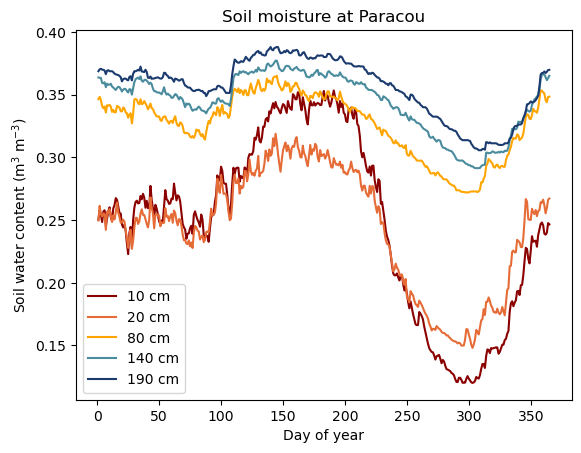

In [24]:
colors = ["darkred", "#E66C37", "orange", "#4A8C9E", "#1B3B6F"]
plt.plot(par_jd,par_avg_10,label='10 cm',color=colors[0])
plt.plot(par_jd,par_avg_20,label='20 cm',color=colors[1])
plt.plot(par_jd,par_avg_80,label='80 cm',color=colors[2])
plt.plot(par_jd,par_avg_140,label='140 cm',color=colors[3])
plt.plot(par_jd,par_avg_190,label='190 cm',color=colors[4])
plt.legend()
plt.title("Soil moisture at Paracou")
plt.xlabel("Day of year")
plt.ylabel("Soil water content (m$^3$ m$^{-3}$)")


In [35]:
month=np.linspace(1,12,12).astype(int)

Text(0, 0.5, 'Soil saturation (%)')

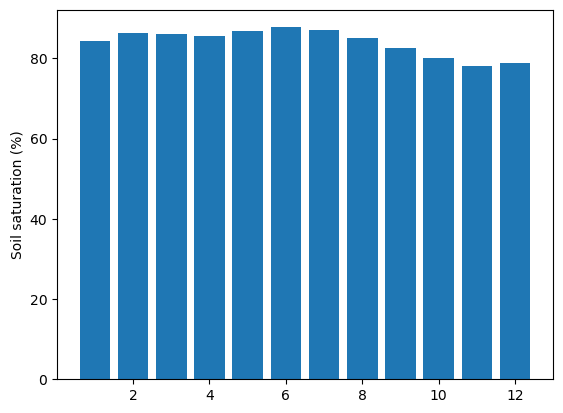

In [37]:
plt.bar(month,all_sites_soil_sat.sel(site="par").values)
plt.ylabel("Soil saturation (%)")

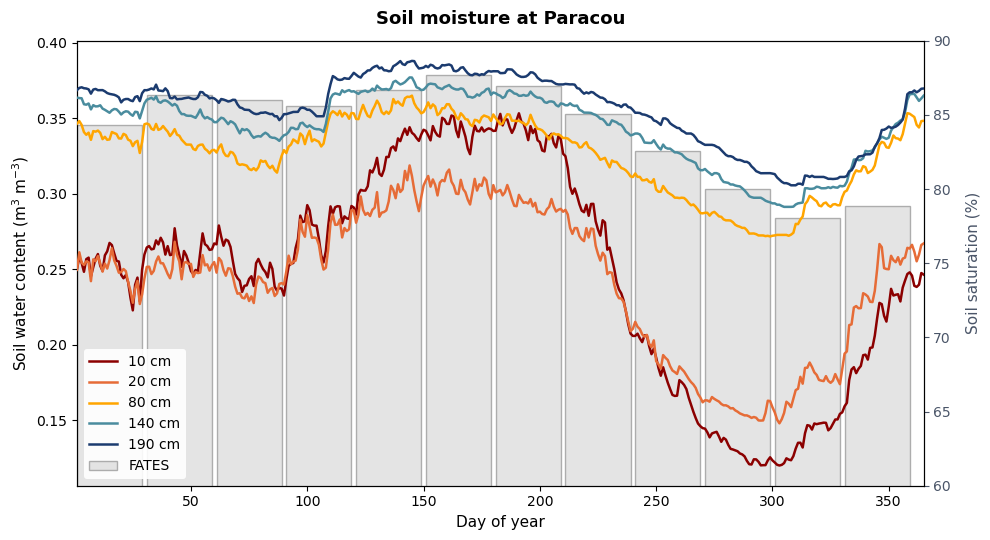

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Setup figure and primary axis (for lines)
fig, ax1 = plt.subplots(figsize=(10, 5.5), facecolor="white")
ax1.set_facecolor("white")

# 2. Setup secondary axis (for bars)
ax2 = ax1.twinx()

# -------------------------------------------------------------
# Background Bars on ax2 (Soil Saturation)
# -------------------------------------------------------------
# If 'month' is 1-12, map to approximate mid-month day-of-year (DOY):
# Jan ~ 15, Feb ~ 45, Mar ~ 74, etc.
month_mid_doy = np.array([15, 45, 75, 105, 135, 165, 195, 225, 255, 285, 315, 345])
bar_values = all_sites_soil_sat.sel(site="par").values

bars = ax2.bar(
    month_mid_doy,
    bar_values,
    width=28,  # Bar width in days
    color="lightgrey",  
    edgecolor="grey",
    alpha=0.6,
    label="FATES",
    zorder=1,
)

ax2.set_ylabel("Soil saturation (%)", color="#4A5568", fontsize=11, labelpad=10)
ax2.tick_params(axis="y", colors="#4A5568")
ax2.grid(False)  # Avoid conflicting grid lines from the twin axis
ax2.set_ylim(60,90)
# -------------------------------------------------------------
# Foreground Lines on ax1 (Soil Water Content)
# -------------------------------------------------------------
colors = ["darkred", "#E66C37", "orange", "#4A8C9E", "#1B3B6F"]

l1 = ax1.plot(par_jd, par_avg_10, label="10 cm", color=colors[0], linewidth=1.8, zorder=3)
l2 = ax1.plot(par_jd, par_avg_20, label="20 cm", color=colors[1], linewidth=1.8, zorder=3)
l3 = ax1.plot(par_jd, par_avg_80, label="80 cm", color=colors[2], linewidth=1.8, zorder=3)
l4 = ax1.plot(par_jd, par_avg_140, label="140 cm", color=colors[3], linewidth=1.8, zorder=3)
l5 = ax1.plot(par_jd, par_avg_190, label="190 cm", color=colors[4], linewidth=1.8, zorder=3)

ax1.set_xlabel("Day of year", fontsize=11)
ax1.set_ylabel("Soil water content (m$^3$ m$^{-3}$)", fontsize=11)
ax1.set_xlim(1, 365)
ax1.set_title("Soil moisture at Paracou", fontsize=13, weight="bold", pad=12)

# Ensure lines on ax1 render above ax2 elements
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)  # Keeps ax1 transparent so ax2 bars show through

# -------------------------------------------------------------
# Unified Legend
# -------------------------------------------------------------
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="lower left",
    frameon=True,
    facecolor="white",
    framealpha=0.9,
    edgecolor="none",
)

plt.tight_layout()
plt.show()

In [29]:
all_sites_soil_sat.sel(site="par")

<xarray.DataArray (month: 12)>
array([84.32671 , 86.36824 , 86.024994, 85.60786 , 86.677025, 87.7188  ,
       86.96405 , 85.03958 , 82.56222 , 79.97646 , 78.06622 , 78.857086],
      dtype=float32)
Coordinates:
    lon      float32 307.5
    lat      float32 4.737
  * month    (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
    site     <U3 'par'

In [21]:
## read in Tapajos flux tower data

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
tap_file='Tapajos/Tapajos_flux_tower_data_EC.prerelease/km67.eddyflux.txt' 

tap_df = pd.read_csv(flx_path+tap_file, sep=',')

# Missing data in the input file is indicated by 999.99
tap_df = tap_df.replace(999.99, np.nan) 

# =====================================================================
# TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
# Calculate total raw rows per day across all years
raw_counts_per_day = tap_df.groupby(['YYYY', 'JD']).size()
avg_raw_rows = raw_counts_per_day.mean()

print("--- Tapajos Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_raw_rows:.2f}")

if 22 <= avg_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print("-> Warning: Unexpected row count. Verify dataset formatting.")
print("------------------------------------------\n")

--- Tapajos Temporal Resolution Check ---
Average raw data rows per day: 24.00
-> Resolution looks to be HOURLY (Target perfect day = 24 rows)
-> Suggested diurnal filter threshold: 19 rows (~80%)
------------------------------------------



In [43]:
tap_df.columns.tolist()

['hours',
 'jdstart.gmt',
 'YYYY',
 'JD',
 'HRMI',
 'ws',
 'wdir',
 't.c',
 'rh',
 'tson',
 'tasp',
 'fheat',
 'fmom',
 'co2',
 'fco2',
 'h2o.mmol.m',
 'fh2o',
 'h2o.mix',
 'pamb.pa',
 'H',
 'LHdry',
 'ustar',
 'ppm2umol',
 'netrad',
 'snetrad',
 'netrad.cal',
 'par',
 'spar1up',
 'par2up',
 'spar2up',
 'par1dn',
 'spar1dn',
 'par.cal',
 'tair1',
 'tair2',
 'tair3',
 'tair4',
 'tair5',
 'tair6',
 'tair7',
 'tair8',
 'ws1',
 'sws1',
 'ws2',
 'sws2',
 'ws3',
 'sws3',
 'ws4',
 'sws4',
 'rain',
 'tot.sun',
 'dif.sun',
 'e_sat',
 'RH.ec',
 'VPD.ec',
 'u',
 'v',
 'w',
 'u.std',
 'v.std',
 'w.std',
 'CO2col.wt',
 'storage.wt',
 'co2.pf.1',
 'co2.pf.2',
 'co2.pf.3',
 'co2.pf.4',
 'co2.pf.5',
 'co2.pf.6',
 'co2.pf.7',
 'co2.pf.8',
 'H2Ocol.wt',
 'H2Ostorage.wt',
 'h2o.pf.1',
 'h2o.pf.2',
 'h2o.pf.3',
 'h2o.pf.4',
 'h2o.pf.5',
 'h2o.pf.6',
 'h2o.pf.7',
 'h2o.pf.8',
 'nee',
 'nee.fill',
 'r',
 'gee',
 'par.fill',
 'TOA',
 'nee.fill.light',
 'r.light',
 'gee.fill.light',
 'stg.filled']

In [44]:

# =====================================================================
# 1. RUN DIURNAL COVERAGE FILTER FIRST
# =====================================================================
# Count valid timesteps for each variable independently per Day of Year (JD)
# (If 30-min data, require >= 38. If hourly, require >= 19)
tap_df['rad_Counts'] = tap_df.groupby(['YYYY', 'JD'])['par'].transform('count')
tap_df['vpd_Counts']  = tap_df.groupby(['YYYY', 'JD'])['VPD.ec'].transform('count')

diurnal_mask_rad = tap_df['rad_Counts'] >= 19
diurnal_mask_vpd  = tap_df['vpd_Counts'] >= 19

# =====================================================================
# 2. COMBINE WITH LEAP DAY FILTER FOR SEPARATE SUBSETS
# =====================================================================
is_leap_year = (tap_df['YYYY'] % 4 == 0)
is_leap_day = (tap_df['JD'] == 60)
not_leap_day = ~(is_leap_year & is_leap_day)

keep_rad_mask = not_leap_day & diurnal_mask_rad
keep_vpd_mask  = not_leap_day & diurnal_mask_vpd

# Extract separate subsets
df_rad_sub = tap_df[keep_rad_mask].copy()
df_vpd_sub  = tap_df[keep_vpd_mask].copy()

# =====================================================================
# 3. SHIFT THE REMAINING DAYS IN LEAP YEARS (For both streams)
# =====================================================================
tap_year_rad = df_rad_sub['YYYY'].values
raw_jd_rad = df_rad_sub['JD'].values
tap_jd_rad = np.where((tap_year_rad % 4 == 0) & (raw_jd_rad > 60), raw_jd_rad - 1, raw_jd_rad)

tap_year_vpd = df_vpd_sub['YYYY'].values
raw_jd_vpd = df_vpd_sub['JD'].values
tap_jd_vpd = np.where((tap_year_vpd % 4 == 0) & (raw_jd_vpd > 60), raw_jd_vpd - 1, raw_jd_vpd)

# Extract final raw arrays from their respective clean subsets
tap_rad = df_rad_sub['par'].values #umol/m2/s
tap_vpd = df_vpd_sub['VPD.ec'].values #kPa

# =====================================================================
# 4. CALCULATE YEARLY CYCLE WITH SEPARATE STREAM INDICES
# =====================================================================
# Master day array is always 1 to 365
tap_jd = np.arange(1, 366)

tap_avg_rad = np.zeros(len(tap_jd))
tap_std_rad = np.zeros(len(tap_jd))
tap_avg_vpd  = np.zeros(len(tap_jd))
tap_std_vpd  = np.zeros(len(tap_jd))

for i in range(len(tap_jd)): 
    # Find indices using separate stream day arrays
    ind_rad = np.where(tap_jd_rad == tap_jd[i])
    ind_vpd  = np.where(tap_jd_vpd == tap_jd[i])
    
    if len(ind_rad[0]) > 0:
        tap_avg_rad[i] = np.nanmean(tap_rad[ind_rad[0]]) 
        tap_std_rad[i] = np.nanstd(tap_rad[ind_rad[0]]) 
    else:
        tap_avg_rad[i], tap_std_rad[i] = np.nan, np.nan
        
    if len(ind_vpd[0]) > 0:
        tap_avg_vpd[i]  = np.nanmean(tap_vpd[ind_vpd[0]])
        tap_std_vpd[i]  = np.nanstd(tap_vpd[ind_vpd[0]])
    else:
        tap_avg_vpd[i], tap_std_vpd[i] = np.nan, np.nan

In [45]:
## read in Tanguro flux tower data

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
tan_file='Tanguro/EC_Control_2014-2024_GAPFILLED_Final.csv'
# missing values are NaNs

# Read in data frame for Tanguro
tan_df = pd.read_csv(flx_path+tan_file, sep=',')

# =====================================================================
# TANGURO TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
# Count total raw rows per calendar date across the entire timeseries
tan_raw_counts_per_day = tan_df.groupby(['Year', 'Day']).size()
avg_tan_raw_rows = tan_raw_counts_per_day.mean()

print("--- Tanguro Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_tan_raw_rows:.2f}")

if 22 <= avg_tan_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_tan_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print(f"-> Warning: Unexpected row count ({avg_tan_raw_rows:.1f}). Verify dataset structure.")
print("------------------------------------------\n")

/tmp/ipykernel_2268287/2034533611.py:8: DtypeWarning: Columns (113,114,213) have mixed types. Specify dtype option on import or set low_memory=False.
  tan_df = pd.read_csv(flx_path+tan_file, sep=',')


--- Tanguro Temporal Resolution Check ---
Average raw data rows per day: 48.00
-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)
-> Suggested diurnal filter threshold: 38 rows (~80%)
------------------------------------------



In [46]:
## calculate vpd
#tempK=tan_df['atm.tmp']
#spcHum=tan_df['atm.shv'] # kg/kg

## Tetens eq.
#esat=0.61078*np.exp((17.269*(tempK-273.15))/((tempK-273.15)+237.3))

#ea = (1204*spcHum*(tempK-273.15)/216.7)
#tan_df['vpd']=esat - ea

# Count valid timesteps per day for each variable
tan_df['vpd_Counts'] = tan_df.groupby(['Year', 'Day'])['VPD'].transform('count')
tan_df['rad_Counts'] = tan_df.groupby(['Year', 'Day'])['Rg'].transform('count')

# Create separate diurnal masks (e.g., require >= 38 periods out of 48)
diurnal_mask_vpd  = tan_df['vpd_Counts'] >= 38
diurnal_mask_rad = tan_df['rad_Counts'] >= 38

# 3. Combine with Leap Day Filter to create SEPARATE row masks
is_leap_year = (tan_df['Year'] % 4 == 0)
is_leap_day = (tan_df['Day'] == 60)
not_leap_day = ~(is_leap_year & is_leap_day)

keep_rad_mask = not_leap_day & diurnal_mask_rad
keep_vpd_mask  = not_leap_day & diurnal_mask_vpd

# 4. Extract separate cleaned subsets
df_rad_sub = tan_df[keep_rad_mask].copy()
df_vpd_sub  = tan_df[keep_vpd_mask].copy()

# =====================================================================
# 5. SHIFT THE REMAINING DAYS IN LEAP YEARS (Do this for both streams)
# =====================================================================
tan_year_rad = df_rad_sub['Year'].values
raw_jd_rad = df_rad_sub['Day'].values
jd_all_rad = np.where((tan_year_rad % 4 == 0) & (raw_jd_rad > 60), raw_jd_rad - 1, raw_jd_rad)

tan_year_vpd = df_vpd_sub['Year'].values
raw_jd_vpd = df_vpd_sub['Day'].values
jd_all_vpd = np.where((tan_year_vpd % 4 == 0) & (raw_jd_vpd > 60), raw_jd_vpd - 1, raw_jd_vpd)

# Extract your raw data arrays
tan_rad = df_rad_sub['Rg'].values 
tan_vpd  = df_vpd_sub['VPD'].values

# Your master 1-365 coordinate list for the loop remains the same
tan_jd = np.arange(1, 366)

# Initialize your empty 365-day arrays
tan_avg_rad = np.zeros(365)
tan_std_rad = np.zeros(365)
tan_avg_vpd = np.zeros(365)
tan_std_vpd = np.zeros(365)

for i in range(len(tan_jd)):
    # Find indices using the separate stream arrays
    ind_rad = np.where(jd_all_rad == tan_jd[i])
    ind_vpd = np.where(jd_all_vpd == tan_jd[i])
    
    if len(ind_rad[0]) > 0:
        tan_avg_rad[i] = np.nanmean(tan_rad[ind_rad[0]])
        tan_std_rad[i] = np.nanstd(tan_rad[ind_rad[0]])
    else:
        tan_avg_rad[i], tan_std_rad[i] = np.nan, np.nan
        
    if len(ind_vpd[0]) > 0:
        tan_avg_vpd[i] = np.nanmean(tan_vpd[ind_vpd[0]])
        tan_std_vpd[i] = np.nanstd(tan_vpd[ind_vpd[0]])
    else:
        tan_avg_vpd[i], tan_std_vpd[i] = np.nan, np.nan

In [47]:
## K34 site

flx_path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/FluxTower/'
k34_file='K34/Prev/AMF_BR-Ma2_BASE_HH_1-5.csv'
# HH means records half-hourly
# Missing data records are indicated by the -9999 value.

# Read in K34 dataframe:
k34_df = pd.read_csv(flx_path+k34_file, sep=',', skiprows=2)

# 1. Pull the raw, unfiltered data from the dataframe
k34_rad_raw = k34_df['SW_IN_PI_F'].values #W/m2
k34_vpd_raw = k34_df['VPD_PI_F'].values  
timestamps_raw = k34_df['TIMESTAMP_START'].values

# Parse raw dates immediately so we have access to calendar Year and DOY
dt_raw = pd.to_datetime(timestamps_raw, format='%Y%m%d%H%M')

# =====================================================================
# K34 TIME RESOLUTION & ROW COUNTER DIAGNOSTIC
# =====================================================================
# Group the dataset by the calendar year and day extracted from dt_raw
k34_raw_counts_per_day = k34_df.groupby([dt_raw.year, dt_raw.dayofyear]).size()
avg_k34_raw_rows = k34_raw_counts_per_day.mean()

print("--- K34 Temporal Resolution Check ---")
print(f"Average raw data rows per day: {avg_k34_raw_rows:.2f}")

if 22 <= avg_k34_raw_rows <= 26:
    print("-> Resolution looks to be HOURLY (Target perfect day = 24 rows)")
    print("-> Suggested diurnal filter threshold: 19 rows (~80%)")
elif 46 <= avg_k34_raw_rows <= 50:
    print("-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)")
    print("-> Suggested diurnal filter threshold: 38 rows (~80%)")
else:
    print(f"-> Warning: Unexpected row count ({avg_k34_raw_rows:.1f}). Verify dataset structure.")
print("--------------------------------------\n")

--- K34 Temporal Resolution Check ---
Average raw data rows per day: 48.00
-> Resolution looks to be HALF-HOURLY (Target perfect day = 48 rows)
-> Suggested diurnal filter threshold: 38 rows (~80%)
--------------------------------------



In [48]:
# 2. RUN DIURNAL COVERAGE FILTER FIRST
df_check = pd.DataFrame({
    'rad': k34_rad_raw,
    'vpd' : k34_vpd_raw,
    'Year': dt_raw.year,
    'DOY': dt_raw.dayofyear
})
df_check['rad'] = df_check['rad'].replace(-9999, np.nan)
df_check['vpd'] = df_check['vpd'].replace(-9999, np.nan)

# Count valid timesteps for each variable independently
df_check['rad_Valid_Counts'] = df_check.groupby(['Year', 'DOY'])['rad'].transform('count')
df_check['vpd_Valid_Counts'] = df_check.groupby(['Year', 'DOY'])['vpd'].transform('count')

diurnal_mask_rad = df_check['rad_Valid_Counts'] >= 38
diurnal_mask_vpd  = df_check['vpd_Valid_Counts'] >= 38

# 3. COMBINE DIURNAL FILTER WITH VALID DATA FILTER (Row must be valid data AND pass diurnal threshold)
valid_rad_mask = (k34_rad_raw != -9999) & diurnal_mask_rad
valid_vpd_mask  = (k34_vpd_raw != -9999) & diurnal_mask_vpd

# 4. PARSE TIMESTAMPS AND APPLY LEAP DAY MASKS SEPARATELY
dt_rad = pd.to_datetime(timestamps_raw[valid_rad_mask], format='%Y%m%d%H%M')
keep_day_rad = ~((dt_rad.year % 4 == 0) & (dt_rad.dayofyear == 60))

k34_rad = k34_rad_raw[valid_rad_mask][keep_day_rad]

rad_year = dt_rad[keep_day_rad].year.values
rad_raw_doy = dt_rad[keep_day_rad].dayofyear.values
k34_doy_rad = np.where((rad_year % 4 == 0) & (rad_raw_doy > 60), rad_raw_doy - 1, rad_raw_doy)

dt_vpd = pd.to_datetime(timestamps_raw[valid_vpd_mask], format='%Y%m%d%H%M')
keep_day_vpd = ~((dt_vpd.year % 4 == 0) & (dt_vpd.dayofyear == 60))

k34_vpd = k34_vpd_raw[valid_vpd_mask][keep_day_vpd]

vpd_year = dt_vpd[keep_day_vpd].year.values
vpd_raw_doy = dt_vpd[keep_day_vpd].dayofyear.values
k34_doy_vpd = np.where((vpd_year % 4 == 0) & (vpd_raw_doy > 60), vpd_raw_doy - 1, vpd_raw_doy)


# =====================================================================
# 5. CALCULATE YEARLY CYCLE WITH SEPARATE STREAM INDICES
# =====================================================================
# Master day array is always 1 to 355
k34_jd = np.arange(1, 366)

k34_avg_rad = np.zeros(len(k34_jd))
k34_std_rad = np.zeros(len(k34_jd))
k34_avg_vpd  = np.zeros(len(k34_jd))
k34_std_vpd  = np.zeros(len(k34_jd))

for i in range(len(k34_jd)):  
    # Find indices using separate stream DOY arrays
    ind_rad = np.where(k34_doy_rad == k34_jd[i])
    ind_vpd  = np.where(k34_doy_vpd == k34_jd[i])
    
    if len(ind_rad[0]) > 0:
        k34_avg_rad[i] = np.nanmean(k34_rad[ind_rad[0]]) 
        k34_std_rad[i] = np.nanstd(k34_rad[ind_rad[0]]) 
    else:
        k34_avg_rad[i], k34_std_rad[i] = np.nan, np.nan
        
    if len(ind_vpd[0]) > 0:
        k34_avg_vpd[i]  = np.nanmean(k34_vpd[ind_vpd[0]])
        k34_std_vpd[i]  = np.nanstd(k34_vpd[ind_vpd[0]])
    else:
        k34_avg_vpd[i], k34_std_vpd[i] = np.nan, np.nan

In [49]:
## Plot everything!

In [50]:
par_ymin_rad=100
par_ymax_rad=300

k34_ymin_rad=100
k34_ymax_rad=300

tap_ymin_rad=100
tap_ymax_rad=300

tan_ymin_rad=100
tan_ymax_rad=300


In [58]:
par_ymin_vpd=0
par_ymax_vpd=3

k34_ymin_vpd=0
k34_ymax_vpd=3

tap_ymin_vpd=0
tap_ymax_vpd=3

tan_ymin_vpd=0
tan_ymax_vpd=3


In [ ]:
## Tavares et al (2023): dry season where monthly precip is below 100 mm
gswp_rain_par

In [ ]:
gswp_rain_k34

In [ ]:
gswp_rain_tap

In [ ]:
gswp_rain_tan

In [59]:
from matplotlib.patches import Rectangle
color='burlywood'
dpm=np.max(fates_days)/12.

gswp_par_dry_rad=Rectangle((9*dpm,par_ymin_rad),2*dpm,par_ymax_rad-par_ymin_rad, facecolor=color, alpha=0.5)
gswp_k34_dry_rad=Rectangle((7*dpm,k34_ymin_rad),3*dpm,k34_ymax_rad-k34_ymin_rad, facecolor=color, alpha=0.5)
gswp_tap_dry1_rad=Rectangle((0*dpm,tap_ymin_rad),1*dpm,tap_ymax_rad-tap_ymin_rad, facecolor=color, alpha=0.5)
gswp_tap_dry2_rad=Rectangle((8*dpm,tap_ymin_rad),4*dpm,tap_ymax_rad-tap_ymin_rad, facecolor=color, alpha=0.5)
gswp_tan_dry_rad=Rectangle((5*dpm,tan_ymin_rad),5*dpm,tan_ymax_rad-tan_ymin_rad, facecolor=color, alpha=0.5)

gswp_par_dry_vpd=Rectangle((9*dpm,par_ymin_vpd),2*dpm,par_ymax_vpd-par_ymin_vpd, facecolor=color, alpha=0.5)
gswp_k34_dry_vpd=Rectangle((7*dpm,k34_ymin_vpd),3*dpm,k34_ymax_vpd-k34_ymin_vpd, facecolor=color, alpha=0.5)
gswp_tap_dry1_vpd=Rectangle((0*dpm,tap_ymin_vpd),1*dpm,tap_ymax_vpd-tap_ymin_vpd, facecolor=color, alpha=0.5)
gswp_tap_dry2_vpd=Rectangle((8*dpm,tap_ymin_vpd),4*dpm,tap_ymax_vpd-tap_ymin_vpd, facecolor=color, alpha=0.5)
gswp_tan_dry_vpd=Rectangle((5*dpm,tan_ymin_vpd),5*dpm,tan_ymax_vpd-tan_ymin_vpd, facecolor=color, alpha=0.5)


In [60]:
# make nice plots
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 10
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300  # Set default DPI to 300 for poster figures

/tmp/ipykernel_2268287/3468779663.py:110: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


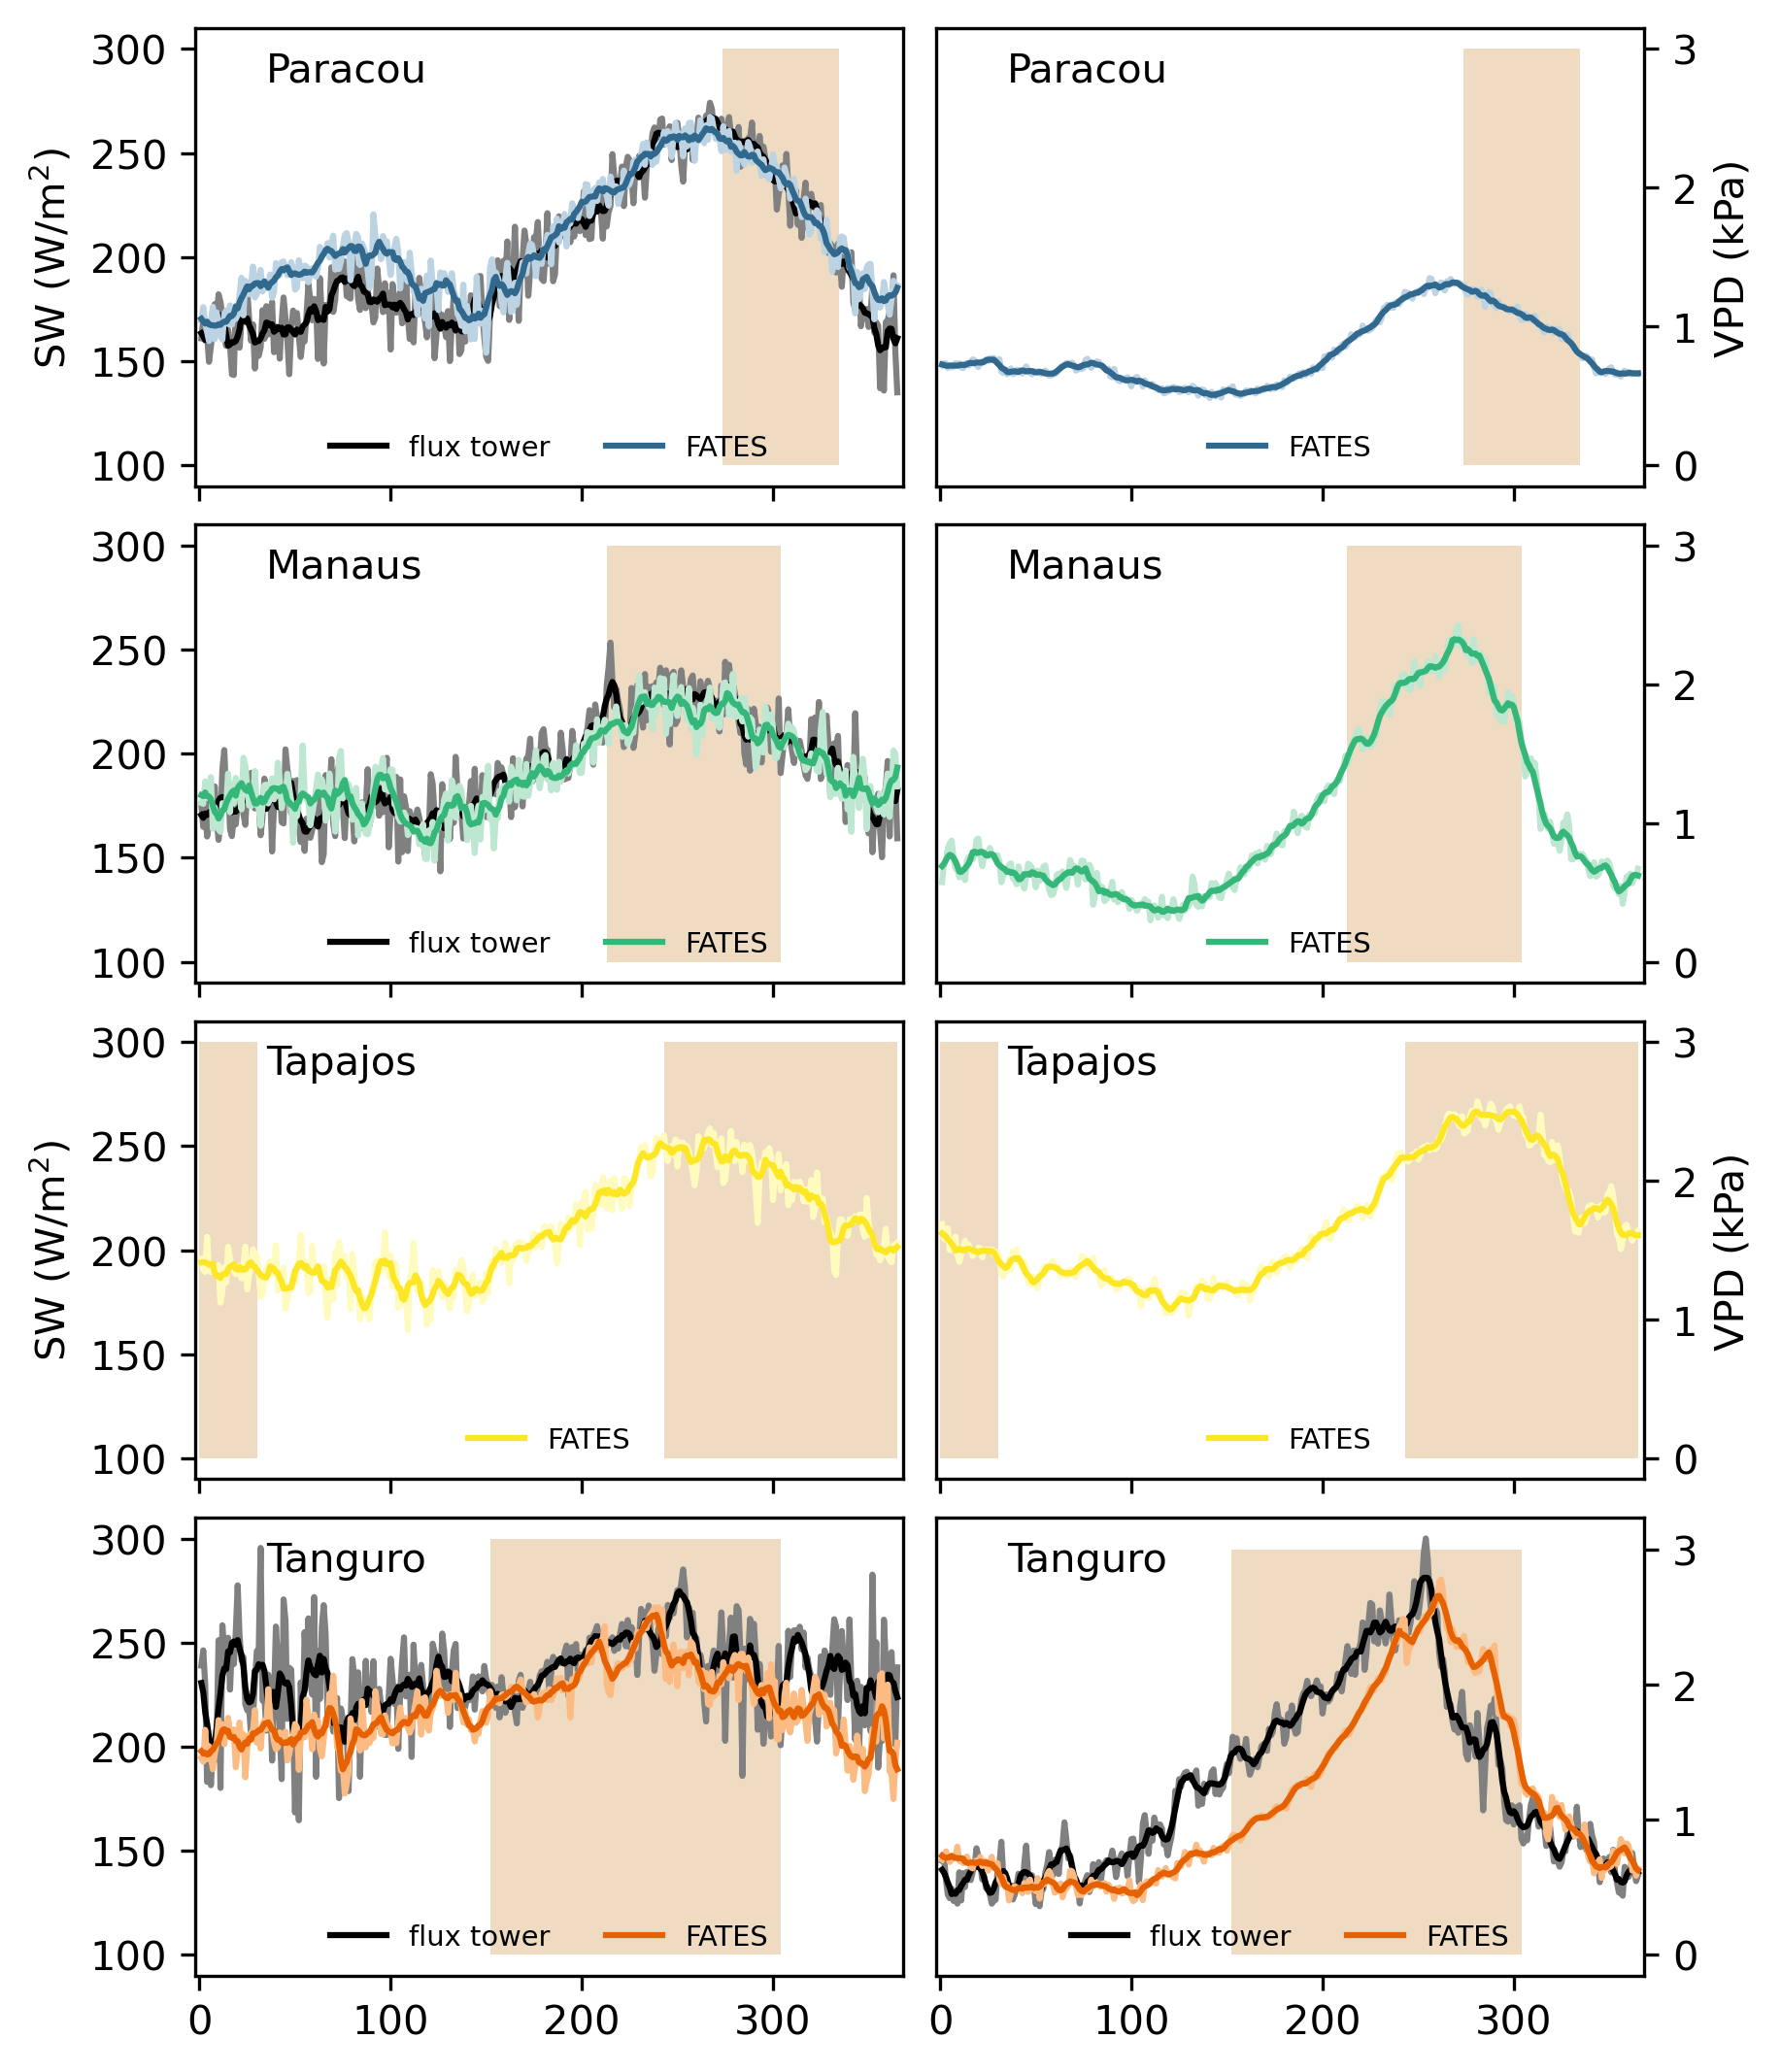

In [61]:
# Order from most to least mean annual rainfall
# add light brown bar showing dry season
# version without residuals

fig, axes = plt.subplots(4,2, figsize=(6,7), sharex=True)

# Columns = SW rad, VPD
# Rows = Paracou, Manaus (K34), Tapajos, Tanguro, residuals (all)

# color scheme: observations = black
# Custom 4-color palette from Wet to Dry
# Order: Paracou (wettest) -> Manaus -> Tapajos -> Tanguro (driest)
site_colors = ['#31688e', '#35b779', '#fde725','#e66101']
shading_colors = ['#bcd3e3', '#bee7d2','#fffbbf','#fdbb84']

### Row 1 - Paracou ###
# Col 1: rad
axes[0,0].add_patch(gswp_par_dry_rad)
axes[0,0].plot(par_jd, par_avg_rad, color="grey")
axes[0,0].plot(par_jd, uniform_filter1d(par_avg_rad, size=7), color="black", label="flux tower")
axes[0,0].plot(fates_days, all_sites_rad.sel(site="par").values, color=shading_colors[0])
axes[0,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="par").values, size=7), color=site_colors[0], label="FATES")
axes[0,0].set_ylabel('SW (W/m$^2$)')
axes[0,0].text(0.1, 0.95, 'Paracou', transform=axes[0,0].transAxes, va='top', ha='left')
axes[0,0].set_xlim(-2,368)
axes[0,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)
    
# Col 2: VPD
axes[0,1].add_patch(gswp_par_dry_vpd)
#axes[0,1].plot(par_jd, par_avg_vpd, color="grey")
#axes[0,1].plot(par_jd, uniform_filter1d(par_avg_vpd, size=7), color="black", label="flux tower")
axes[0,1].plot(fates_days, all_sites_vpd.sel(site="par").values, color=shading_colors[0])
axes[0,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="par").values, size=7), color=site_colors[0], label="FATES")
axes[0,1].set_ylabel('VPD (kPa)')
axes[0,1].text(0.1, 0.95, 'Paracou', transform=axes[0,1].transAxes, va='top', ha='left')
axes[0,1].set_xlim(-2,368)
axes[0,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[0,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[0,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 2 - K34 Manaus ###
## col 1: rad
axes[1,0].add_patch(gswp_k34_dry_rad)
axes[1,0].plot(k34_jd, k34_avg_rad, color="grey")
axes[1,0].plot(k34_jd, uniform_filter1d(k34_avg_rad, size=7), color="black", label="flux tower")
axes[1,0].plot(fates_days, all_sites_rad.sel(site="k34").values, color=shading_colors[1])
axes[1,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="k34").values, size=7), color=site_colors[1], label="FATES")
axes[1,0].text(0.1, 0.95, 'Manaus', transform=axes[1,0].transAxes, va='top', ha='left')
axes[1,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[1,1].add_patch(gswp_k34_dry_vpd)
#axes[1,1].plot(k34_jd, k34_avg_vpd, color="grey")
#axes[1,1].plot(k34_jd, uniform_filter1d(k34_avg_vpd, size=7), color="black", label="flux tower")
axes[1,1].plot(fates_days, all_sites_vpd.sel(site="k34").values, color=shading_colors[1])
axes[1,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="k34").values, size=7), color=site_colors[1], label="FATES")
axes[1,1].text(0.1, 0.95, 'Manaus', transform=axes[1,1].transAxes, va='top', ha='left')
axes[1,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[1,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[1,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 3 - Tapajos ###
## col 1: rad
axes[2,0].add_patch(gswp_tap_dry1_rad)
axes[2,0].add_patch(gswp_tap_dry2_rad)
#axes[2,0].plot(tap_jd, tap_avg_rad, color="grey")
#axes[2,0].plot(tap_jd, uniform_filter1d(tap_avg_rad, size=7), color="black", label="flux tower")
axes[2,0].plot(fates_days, all_sites_rad.sel(site="tap").values, color=shading_colors[2])
axes[2,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="tap").values, size=7), color=site_colors[2], label="FATES")
axes[2,0].set_ylabel('SW (W/m$^2$)')
axes[2,0].text(0.1, 0.95, 'Tapajos', transform=axes[2,0].transAxes, va='top', ha='left')
axes[2,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: vpd
axes[2,1].add_patch(gswp_tap_dry1_vpd)
axes[2,1].add_patch(gswp_tap_dry2_vpd)
#axes[2,1].plot(tap_jd, tap_avg_vpd, color="grey")
#axes[2,1].plot(tap_jd, uniform_filter1d(tap_avg_vpd, size=7), color="black", label="flux tower")
axes[2,1].plot(fates_days, all_sites_vpd.sel(site="tap").values, color=shading_colors[2])
axes[2,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="tap").values, size=7), color=site_colors[2], label="FATES")
axes[2,1].set_ylabel('VPD (kPa)')
axes[2,1].text(0.1, 0.95, 'Tapajos', transform=axes[2,1].transAxes, va='top', ha='left')
axes[2,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[2,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[2,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 4 - Tanguro ###
## col 1: rad
axes[3,0].add_patch(gswp_tan_dry_rad)
axes[3,0].plot(tan_jd, tan_avg_rad, color="grey")
axes[3,0].plot(tan_jd, uniform_filter1d(tan_avg_rad, size=7), color="black", label="flux tower")
axes[3,0].plot(fates_days, all_sites_rad.sel(site="tan").values, color=shading_colors[3])
axes[3,0].plot(fates_days, uniform_filter1d(all_sites_rad.sel(site="tan").values, size=7), color=site_colors[3], label="FATES")
axes[3,0].text(0.1, 0.95, 'Tanguro', transform=axes[3,0].transAxes, va='top', ha='left')
axes[3,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[3,1].add_patch(gswp_tan_dry_vpd)
axes[3,1].plot(tan_jd, tan_avg_vpd, color="grey")
axes[3,1].plot(tan_jd, uniform_filter1d(tan_avg_vpd, size=7), color="black", label="flux tower")
axes[3,1].plot(fates_days, all_sites_vpd.sel(site="tan").values, color=shading_colors[3])
axes[3,1].plot(fates_days, uniform_filter1d(all_sites_vpd.sel(site="tan").values, size=7), color=site_colors[3], label="FATES")
axes[3,1].text(0.1, 0.95, 'Tanguro', transform=axes[3,1].transAxes, va='top', ha='left')
axes[3,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[3,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[3,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)



plt.tight_layout()
plt.show()

In [ ]:
# Order from most to least mean annual rainfall
# add light brown bar showing dry season
# version with residuals

fig, axes = plt.subplots(5,2, figsize=(6,7), sharex=True)

# Columns = SW rad, VPD
# Rows = Paracou, Manaus (K34), Tapajos, Tanguro, residuals (all)

# color scheme: observations = black
# Custom 4-color palette from Wet to Dry
# Order: Paracou (wettest) -> Manaus -> Tapajos -> Tanguro (driest)
site_colors = ['#31688e', '#35b779', '#fde725','#e66101']
shading_colors = ['#bcd3e3', '#bee7d2','#fffbbf','#fdbb84']

### Row 1 - Paracou ###
# Col 1: rad
axes[0,0].add_patch(gswp_par_dry_rad)
axes[0,0].plot(par_jd, par_avg_rad, color="grey")
axes[0,0].plot(par_jd, uniform_filter1d(par_avg_rad, size=7), color="black", label="flux tower")
axes[0,0].plot(fates_days, fates_par_avg_rad, color=shading_colors[0])
axes[0,0].plot(fates_days, uniform_filter1d(fates_par_avg_rad, size=7), color=site_colors[0], label="FATES")
axes[0,0].set_ylabel('SW (W/m$^2$)')
axes[0,0].text(0.1, 0.95, 'Paracou', transform=axes[0,0].transAxes, va='top', ha='left')
axes[0,0].set_xlim(-2,368)
axes[0,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)
    
# Col 2: VPD
axes[0,1].add_patch(gswp_par_dry_vpd)
axes[0,1].plot(par_jd, par_avg_vpd, color="grey")
axes[0,1].plot(par_jd, uniform_filter1d(par_avg_vpd, size=7), color="black", label="flux tower")
axes[0,1].plot(fates_days, fates_par_avg_vpd, color=shading_colors[0])
axes[0,1].plot(fates_days, uniform_filter1d(fates_par_avg_vpd, size=7), color=site_colors[0], label="FATES")
axes[0,1].set_ylabel('VPD (kPa)')
axes[0,1].text(0.1, 0.95, 'Paracou', transform=axes[0,1].transAxes, va='top', ha='left')
axes[0,1].set_xlim(-2,368)
axes[0,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[0,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[0,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 2 - K34 Manaus ###
## col 1: rad
axes[1,0].add_patch(gswp_k34_dry_rad)
axes[1,0].plot(k34_jd, k34_avg_rad, color="grey")
axes[1,0].plot(k34_jd, uniform_filter1d(k34_avg_rad, size=7), color="black", label="flux tower")
axes[1,0].plot(fates_days, fates_k34_avg_rad, color=shading_colors[1])
axes[1,0].plot(fates_days, uniform_filter1d(fates_k34_avg_rad, size=7), color=site_colors[1], label="FATES")
axes[1,0].text(0.1, 0.95, 'Manaus', transform=axes[1,0].transAxes, va='top', ha='left')
axes[1,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[1,1].add_patch(gswp_k34_dry_vpd)
axes[1,1].plot(k34_jd, k34_avg_vpd, color="grey")
axes[1,1].plot(k34_jd, uniform_filter1d(k34_avg_vpd, size=7), color="black", label="flux tower")
axes[1,1].plot(fates_days, fates_k34_avg_vpd, color=shading_colors[1])
axes[1,1].plot(fates_days, uniform_filter1d(fates_k34_avg_vpd, size=7), color=site_colors[1], label="FATES")
axes[1,1].text(0.1, 0.95, 'Manaus', transform=axes[1,1].transAxes, va='top', ha='left')
axes[1,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[1,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[1,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 3 - Tapajos ###
## col 1: rad
axes[2,0].add_patch(gswp_tap_dry1_rad)
axes[2,0].add_patch(gswp_tap_dry2_rad)
axes[2,0].plot(tap_jd, tap_avg_rad, color="grey")
axes[2,0].plot(tap_jd, uniform_filter1d(tap_avg_rad, size=7), color="black", label="flux tower")
axes[2,0].plot(fates_days, fates_tap_avg_rad, color=shading_colors[2])
axes[2,0].plot(fates_days, uniform_filter1d(fates_tap_avg_rad, size=7), color=site_colors[2], label="FATES")
axes[2,0].set_ylabel('SW (W/m$^2$)')
axes[2,0].text(0.1, 0.95, 'Tapajos', transform=axes[2,0].transAxes, va='top', ha='left')
axes[2,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: vpd
axes[2,1].add_patch(gswp_tap_dry1_vpd)
axes[2,1].add_patch(gswp_tap_dry2_vpd)
axes[2,1].plot(tap_jd, tap_avg_vpd, color="grey")
axes[2,1].plot(tap_jd, uniform_filter1d(tap_avg_vpd, size=7), color="black", label="flux tower")
axes[2,1].plot(fates_days, fates_tap_avg_vpd, color=shading_colors[2])
axes[2,1].plot(fates_days, uniform_filter1d(fates_tap_avg_vpd, size=7), color=site_colors[2], label="FATES")
axes[2,1].set_ylabel('VPD (kPa)')
axes[2,1].text(0.1, 0.95, 'Tapajos', transform=axes[2,1].transAxes, va='top', ha='left')
axes[2,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[2,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[2,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

### Row 4 - Tanguro ###
## col 1: rad
axes[3,0].add_patch(gswp_tan_dry_rad)
axes[3,0].plot(tan_jd, tan_avg_rad, color="grey")
axes[3,0].plot(tan_jd, uniform_filter1d(tan_avg_rad, size=7), color="black", label="flux tower")
axes[3,0].plot(fates_days, fates_tan_avg_rad, color=shading_colors[3])
axes[3,0].plot(fates_days, uniform_filter1d(fates_tan_avg_rad, size=7), color=site_colors[3], label="FATES")
axes[3,0].text(0.1, 0.95, 'Tanguro', transform=axes[3,0].transAxes, va='top', ha='left')
axes[3,0].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## col 2: VPD
axes[3,1].add_patch(gswp_tan_dry_vpd)
axes[3,1].plot(tan_jd, tan_avg_vpd, color="grey")
axes[3,1].plot(tan_jd, uniform_filter1d(tan_avg_vpd, size=7), color="black", label="flux tower")
axes[3,1].plot(fates_days, fates_tan_avg_vpd, color=shading_colors[3])
axes[3,1].plot(fates_days, uniform_filter1d(fates_tan_avg_vpd, size=7), color=site_colors[3], label="FATES")
axes[3,1].text(0.1, 0.95, 'Tanguro', transform=axes[3,1].transAxes, va='top', ha='left')
axes[3,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[3,1].yaxis.set_label_position("right")  # <-- Moves label text right
axes[3,1].legend(loc='lower center',ncols=2,fontsize='x-small',frameon=False)

## row 5: residuals
## col 1: rad
axes[4,0].plot(par_jd, uniform_filter1d(100.*(fates_par_avg_rad-par_avg_rad)/(par_avg_rad),size=7), color=site_colors[0],label='Paracou')
axes[4,0].plot(k34_jd, uniform_filter1d(100.*(fates_k34_avg_rad-k34_avg_rad)/(k34_avg_rad),size=7), color=site_colors[1],label='Manaus')
axes[4,0].plot(tap_jd, uniform_filter1d(100.*(fates_tap_avg_rad-tap_avg_rad)/(tap_avg_rad),size=7), color=site_colors[2],label='Tapajos')
axes[4,0].plot(tan_jd, uniform_filter1d(100.*(fates_tan_avg_rad-tan_avg_rad)/(tan_avg_rad),size=7), color=site_colors[3],label='Tanguro')
axes[4,0].set_ylabel('SW % diff.')
axes[4,0].plot(par_jd, 0.*par_jd, color="black",linestyle="dotted")
axes[4,0].set_xlabel('DOY')
axes[4,0].legend(loc='upper left',fontsize='x-small',frameon=False)

## col 2: VPD
axes[4,1].plot(par_jd, uniform_filter1d(100.*(fates_par_avg_vpd-par_avg_vpd)/par_avg_vpd,size=7), color=site_colors[0])
axes[4,1].plot(k34_jd, uniform_filter1d(100.*(fates_k34_avg_vpd-k34_avg_vpd)/k34_avg_vpd,size=7), color=site_colors[1])
axes[4,1].plot(tap_jd, uniform_filter1d(100.*(fates_tap_avg_vpd-tap_avg_vpd)/tap_avg_vpd,size=7), color=site_colors[2])
axes[4,1].plot(tan_jd, uniform_filter1d(100.*(fates_tan_avg_vpd-tan_avg_vpd)/tan_avg_vpd,size=7), color=site_colors[3])
axes[4,1].set_ylabel('VPD % diff.')
axes[4,1].plot(k34_jd, 0.*k34_jd, color="black",linestyle="dotted")
axes[4,1].set_xlabel('DOY')
axes[4,1].yaxis.tick_right()                 # <-- Moves ticks right
axes[4,1].yaxis.set_label_position("right")  # <-- Moves label text right


plt.tight_layout()
plt.show()

In [ ]:
# plot one figure with FATES SW at each site

plt.plot(fates_days, fates_par_avg_rad, color=shading_colors[0])
plt.plot(fates_days, uniform_filter1d(fates_par_avg_rad, size=7), color=site_colors[0], label="Paracou")
plt.ylabel('FATES Incident Solar Radiation (W/m$^2$)')
plt.xlim(-2,368)
plt.plot(fates_days, fates_k34_avg_rad, color=shading_colors[1])
plt.plot(fates_days, uniform_filter1d(fates_k34_avg_rad, size=7), color=site_colors[1], label="Manaus")
plt.plot(fates_days, fates_tap_avg_rad, color=shading_colors[2])
plt.plot(fates_days, uniform_filter1d(fates_tap_avg_rad, size=7), color=site_colors[2], label="Tapajos")
plt.plot(fates_days, fates_tan_avg_rad, color=shading_colors[3])
plt.plot(fates_days, uniform_filter1d(fates_tan_avg_rad, size=7), color=site_colors[3], label="Tanguro")
